# Modelos mais baratos com as mesmas ferramentas: Haiku 5.5 e Sonnet 5.5 × Opus 5.5 (ADR 0023)

**Pergunta do autor (2026-11-20):** um modelo mais barato, com as ferramentas e evidências da A2/A3, consegue se igualar ao Claude Opus 5.5 da E7/E8?

**Análise exploratória (ameaça nº 27).** A pergunta surgiu depois de ver os resultados da E8. O protocolo foi fixado no ADR 0023 antes de rodar cada modelo no teste: primeiro o Haiku, depois o Sonnet, por adendo.

**Protocolo:**
- **Condições:** mesmas variantes (A1, A2, A3), ferramentas, prompts, pacotes de evidência e consultas da E7, com 1 repetição e esforço `medium`. Nenhum ajuste para os modelos mais baratos.
- **Comparação principal de cada modelo:** A3 × A1 (família da E8: diferença pareada da nota parcial, McNemar exato no acerto estrito, Holm).
- **"Igualar o Opus":** não inferioridade com margem de 0,10 na nota parcial oficial, exigida contra **todas** as variantes do Opus (interseção-união). A afirmação vale só para A2 e A3.
- **Calibração, antes das execuções:** no Telecom, nem o Opus passa nesse critério contra si mesmo.
- **Notas:** script oficial do OpenRCA. O Opus, o A0 e a cadeia do pacote sem LLM vêm da E8.

Este notebook lê só as tabelas `reports/tables/model_compare_<sistema>_<modelo>.json` e `agent_eval_<sistema>.json`.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_width_chars(260)

TABLES = Path("reports/tables")
SYSTEMS = ["Telecom", "Bank"]
VARIANTS = ["A1", "A2", "A3"]
CANDIDATES = {"Sonnet": "claude-sonnet-5-5", "Haiku": "claude-haiku-5-5"}
MODELS = ["Opus", *CANDIDATES]
LLM_CHAINS = [f"{m} {v}" for m in MODELS for v in VARIANTS]
CHAINS = ["A0", "pacote", *LLM_CHAINS]

M = {
    (s, m): json.loads((TABLES / f"model_compare_{s}_{slug}.json").read_text(encoding="utf-8"))
    for s in SYSTEMS
    for m, slug in CANDIDATES.items()
}
E = {s: json.loads((TABLES / f"agent_eval_{s}.json").read_text(encoding="utf-8")) for s in SYSTEMS}

# As cadeias do Opus, do A0 e do pacote aparecem nas duas tabelas e têm de ser idênticas às da E8.
for s in SYSTEMS:
    for m in CANDIDATES:
        for c in ["A0", "pacote", *VARIANTS]:
            key = c if c in ("A0", "pacote") else f"Opus {c}"
            for metric in ("partial_score", "strict_accuracy"):
                got = M[(s, m)]["summary"][key][metric]
                assert got == E[s]["summary"][c][metric], (s, m, c, metric)

pl.DataFrame(
    [
        {
            "sistema": s,
            "modelo": m,
            "consultas": M[(s, m)]["queries"],
            **{f"execução {v}": M[(s, m)]["candidate"]["runs"][v] for v in VARIANTS},
            "Opus (E8)": M[(s, m)]["reference"]["e8_run"],
        }
        for s in SYSTEMS
        for m in CANDIDATES
    ]
)

sistema,modelo,consultas,execução A1,execução A2,execução A3,Opus (E8)
str,str,i64,str,str,str,str
"""Telecom""","""Sonnet""",45,"""20261120T200848-agent_a1""","""20261120T202053-agent_a2""","""20261120T202910-agent_a3""","""20261120T071423-agent_eval"""
"""Telecom""","""Haiku""",45,"""20261120T160258-agent_a1""","""20261120T162411-agent_a2""","""20261120T164414-agent_a3""","""20261120T071423-agent_eval"""
"""Bank""","""Sonnet""",120,"""20261120T203920-agent_a1""","""20261120T210725-agent_a2""","""20261121T015443-agent_a3""","""20261120T071429-agent_eval"""
"""Bank""","""Haiku""",120,"""20261120T170250-agent_a1""","""20261120T180501-agent_a2""","""20261120T190157-agent_a3""","""20261120T071429-agent_eval"""


In [2]:
MUTED, INK, INK2, GRID, AXIS, SURFACE = (
    "#898781",
    "#0b0b0b",
    "#52514e",
    "#e1e0d9",
    "#c3c2b7",
    "#fcfcfb",
)
MODEL_COLOR = {"Opus": "#2a78d6", "Sonnet": "#eb6834", "Haiku": "#1baf7a"}
MARKER = {"A1": "o", "A2": "s", "A3": "D"}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
        "figure.dpi": 110,
    }
)


def color(chain):
    if chain == "A0":
        return MUTED
    if chain == "pacote":
        return INK2
    return MODEL_COLOR[chain.split()[0]]


def fmt(d, digits=2):
    return f"{d['value']:.{digits}f} [{d['ci_low']:.{digits}f}; {d['ci_high']:.{digits}f}]"


def pfmt(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def dot_ci(ax, x, y, c, marker="o"):
    ax.errorbar(
        x["value"],
        y,
        xerr=[[x["value"] - x["ci_low"]], [x["ci_high"] - x["value"]]],
        fmt=marker,
        color=c,
        ms=7,
        elinewidth=2,
        capsize=0,
    )


def chain_table(s, key):
    """Value of `key` for every chain of system `s` (Opus, references and both candidates)."""
    out = {}
    for m in CANDIDATES:
        out.update(M[(s, m)][key])
    return out

### Estilo dos gráficos

- **Cor = modelo:** azul para o Opus, laranja para o Sonnet, verde-água para o Haiku. A0 e pacote em cinza.
- **Variante:** escrita no rótulo; nos gráficos com várias variantes juntas, o marcador também muda (círculo A1, quadrado A2, losango A3).
- **Paleta:** a mesma, validada para daltonismo, dos notebooks anteriores. O verde-água tem pouco contraste com o fundo, por isso todo gráfico traz o valor escrito e uma tabela.

## 1. Nota oficial por cadeia

sistema,cadeia,nota parcial [IC 95%],acerto estrito [IC 95%]
str,str,str,str
"""Telecom""","""A0""","""0.18 [0.10; 0.29]""","""0.11 [0.02; 0.22]"""
"""Telecom""","""pacote""","""0.41 [0.29; 0.54]""","""0.29 [0.16; 0.42]"""
"""Telecom""","""Opus A1""","""0.60 [0.46; 0.72]""","""0.51 [0.36; 0.67]"""
"""Telecom""","""Opus A2""","""0.60 [0.48; 0.73]""","""0.49 [0.36; 0.64]"""
"""Telecom""","""Opus A3""","""0.58 [0.44; 0.71]""","""0.49 [0.33; 0.64]"""
"""Telecom""","""Sonnet A1""","""0.17 [0.08; 0.28]""","""0.11 [0.02; 0.20]"""
"""Telecom""","""Sonnet A2""","""0.24 [0.14; 0.36]""","""0.18 [0.07; 0.29]"""
"""Telecom""","""Sonnet A3""","""0.31 [0.20; 0.44]""","""0.22 [0.11; 0.36]"""
"""Telecom""","""Haiku A1""","""0.14 [0.06; 0.23]""","""0.09 [0.02; 0.18]"""


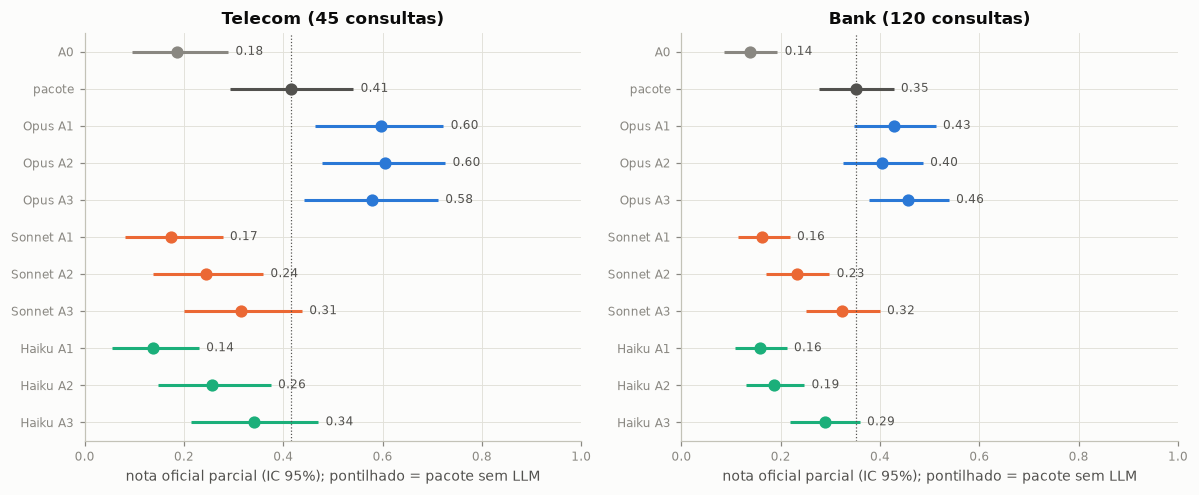

In [3]:
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "cadeia": c,
                "nota parcial [IC 95%]": fmt(chain_table(s, "summary")[c]["partial_score"]),
                "acerto estrito [IC 95%]": fmt(chain_table(s, "summary")[c]["strict_accuracy"]),
            }
            for s in SYSTEMS
            for c in CHAINS
        ]
    )
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    summary = chain_table(s, "summary")
    for i, c in enumerate(CHAINS):
        e = summary[c]["partial_score"]
        dot_ci(ax, e, i, color(c))
        ax.text(e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2)
    ax.axvline(summary["pacote"]["partial_score"]["value"], color=INK2, lw=0.8, ls=":")
    ax.set_yticks(range(len(CHAINS)), CHAINS)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(f"{s} ({M[(s, 'Haiku')]['queries']} consultas)")
    ax.set_xlabel("nota oficial parcial (IC 95%); pontilhado = pacote sem LLM")
fig.tight_layout()

**Leitura:**
- Os dois modelos mais baratos ficam muito abaixo do Opus em todas as variantes.
- Os dois sobem da A1 para a A3.
- O Sonnet A3 e o Haiku A3 terminam perto da cadeia do pacote sem LLM (linha pontilhada).

## 2. A evidência LSTM/XAI ajuda cada modelo? (A3 × A1 e família)

- As comparações dentro de cada modelo são as mesmas da E8: diferença pareada da nota parcial com IC por bootstrap, mais McNemar exato no acerto estrito com Holm nas três comparações.
- Para o Opus, os números são os da E8.

sistema,modelo,comparação,papel,diferença parcial [IC 95%],veredito,McNemar b / c,p (Holm)
str,str,str,str,str,str,str,str
"""Telecom""","""Opus""","""A3 - A1""","""principal""","""-0.018 [-0.129; 0.093]""","""empate""","""4 / 5""","""1.000"""
"""Telecom""","""Opus""","""A2 - A1""","""secundária""","""0.008 [-0.129; 0.148]""","""empate""","""6 / 7""","""1.000"""
"""Telecom""","""Opus""","""A3 - A2""","""secundária""","""-0.026 [-0.141; 0.085]""","""empate""","""4 / 4""","""1.000"""
"""Telecom""","""Sonnet""","""A3 - A1""","""principal""","""0.141 [-0.011; 0.292]""","""empate""","""9 / 4""","""0.801"""
"""Telecom""","""Sonnet""","""A2 - A1""","""secundária""","""0.070 [-0.052; 0.192]""","""empate""","""6 / 3""","""1.000"""
"""Telecom""","""Sonnet""","""A3 - A2""","""secundária""","""0.071 [-0.052; 0.193]""","""empate""","""5 / 3""","""1.000"""
"""Telecom""","""Haiku""","""A3 - A1""","""principal""","""0.204 [0.044; 0.359]""","""superior""","""12 / 3""","""0.105"""
"""Telecom""","""Haiku""","""A2 - A1""","""secundária""","""0.119 [-0.022; 0.263]""","""empate""","""7 / 3""","""0.344"""
"""Telecom""","""Haiku""","""A3 - A2""","""secundária""","""0.085 [-0.000; 0.178]""","""empate""","""5 / 0""","""0.125"""


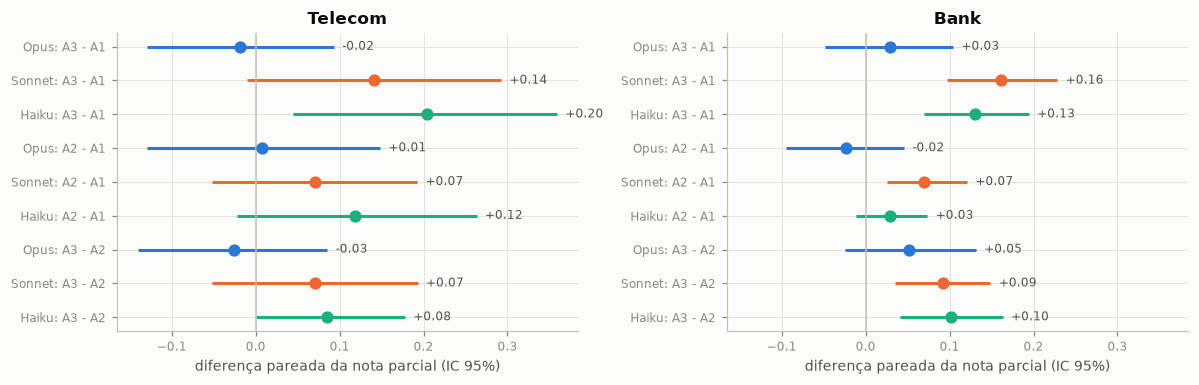

In [4]:
rows = []
for s in SYSTEMS:
    for r in E[s]["comparisons"]:
        rows.append({"sistema": s, "modelo": "Opus", **r})
    for m in CANDIDATES:
        for r in M[(s, m)]["within_candidate"]:
            rows.append(
                {"sistema": s, "modelo": m, **r, "comparison": r["comparison"].replace(f"{m} ", "")}
            )
display(
    pl.DataFrame(
        [
            {
                "sistema": r["sistema"],
                "modelo": r["modelo"],
                "comparação": r["comparison"],
                "papel": "principal" if r["role"] == "primary" else "secundária",
                "diferença parcial [IC 95%]": fmt(r["partial_difference"], 3),
                "veredito": r["verdict"],
                "McNemar b / c": f"{r['mcnemar_only_first']} / {r['mcnemar_only_second']}",
                "p (Holm)": pfmt(r["mcnemar_p_holm"]),
            }
            for r in rows
        ]
    )
)

COMPARISONS = ["A3 - A1", "A2 - A1", "A3 - A2"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    labels = []
    for i, (m, comp) in enumerate((m, c) for c in COMPARISONS for m in MODELS):
        r = next(
            x for x in rows if x["sistema"] == s and x["modelo"] == m and x["comparison"] == comp
        )
        e = r["partial_difference"]
        dot_ci(ax, e, i, MODEL_COLOR[m])
        ax.text(e["ci_high"] + 0.01, i, f"{e['value']:+.2f}", va="center", fontsize=8, color=INK2)
        labels.append(f"{m}: {comp}")
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.set_title(s)
    ax.set_xlabel("diferença pareada da nota parcial (IC 95%)")
fig.tight_layout()

**Leitura:**
- **Opus:** a evidência não teve efeito detectável; as três comparações empatam nos dois sistemas.
- **Modelos mais baratos:** A3 − A1 é positiva nos quatro casos, com +0,13 a +0,20 de diferença. É superior pela diferença pareada em três:
  - Haiku no Telecom e no Bank;
  - Sonnet no Bank.
  - O Sonnet no Telecom fica no limite, com IC de −0,01 a 0,29.
- **McNemar no acerto estrito:** significativo só no Bank.
- **De onde vem o ganho:** dividido entre as duas etapas, com mais peso na A2 → A3.
  - A2 × A1 só é superior no Sonnet do Bank.
  - A3 × A2, com as atribuições SHAP/LIME, é superior no Bank para os dois modelos e empata no Telecom (+0,07 e +0,08).

## 3. Os modelos mais baratos igualam o Opus? (não inferioridade, margem 0,10)

Cada variante candidata é comparada com cada variante do Opus, pela diferença pareada candidato − Opus.

| Veredito | Condição |
|---|---|
| **não inferior** | limite inferior do IC > −0,10 |
| **inferior** | limite superior < −0,10 |
| **inconclusivo** | nos demais casos |

"Iguala o Opus" exige "não inferior" contra as três variantes do Opus.

sistema,comparação,diferença parcial [IC 95%],não inferioridade,veredito usual
str,str,str,str,str
"""Telecom""","""Sonnet A1 - Opus A1""","""-0.422 [-0.563; -0.281]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A1 - Opus A2""","""-0.430 [-0.560; -0.307]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A1 - Opus A3""","""-0.404 [-0.530; -0.278]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A2 - Opus A1""","""-0.352 [-0.500; -0.193]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A2 - Opus A2""","""-0.360 [-0.500; -0.222]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A2 - Opus A3""","""-0.334 [-0.474; -0.197]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A3 - Opus A1""","""-0.281 [-0.437; -0.122]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A3 - Opus A2""","""-0.289 [-0.426; -0.159]""","""inferior""","""inferior"""
"""Telecom""","""Sonnet A3 - Opus A3""","""-0.263 [-0.396; -0.137]""","""inferior""","""inferior"""


sistema,modelo,A1,A2,A3
str,str,str,str,str
"""Telecom""","""Sonnet""","""não (só contexto)""","""não""","""não"""
"""Telecom""","""Haiku""","""não (só contexto)""","""não""","""não"""
"""Bank""","""Sonnet""","""não (só contexto)""","""não""","""não"""
"""Bank""","""Haiku""","""não (só contexto)""","""não""","""não"""


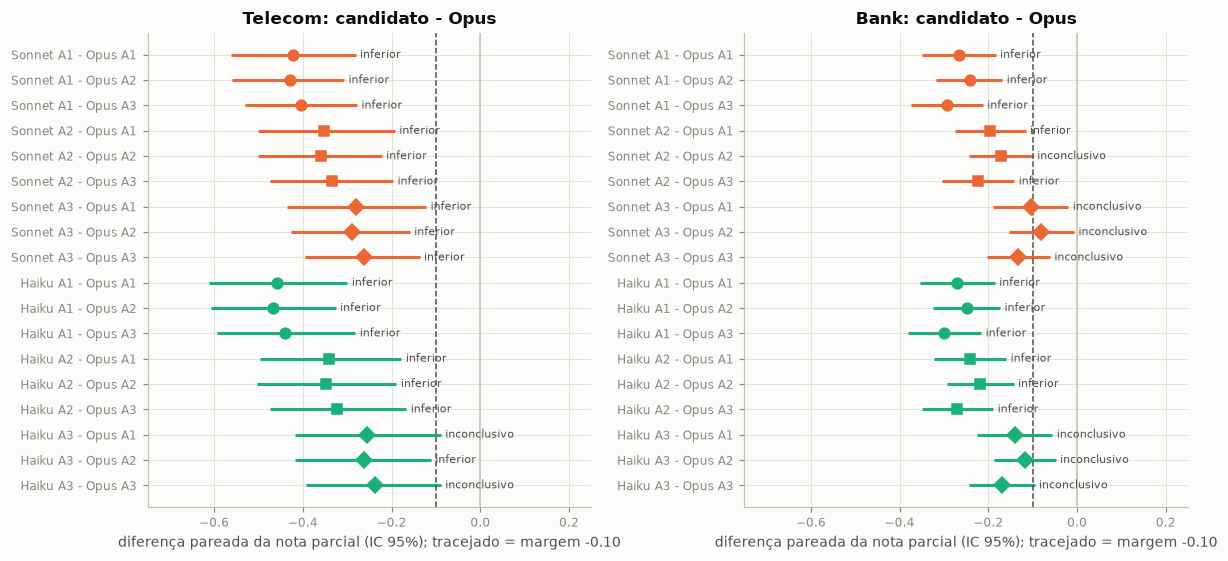

In [5]:
vs = [
    {"sistema": s, "modelo": m, **r}
    for s in SYSTEMS
    for m in CANDIDATES
    for r in M[(s, m)]["versus_reference"]
]
display(
    pl.DataFrame(
        [
            {
                "sistema": r["sistema"],
                "comparação": r["comparison"],
                "diferença parcial [IC 95%]": fmt(r["partial_difference"], 3),
                "não inferioridade": r["noninferiority"],
                "veredito usual": r["verdict"],
            }
            for r in vs
        ]
    )
)
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "modelo": m,
                **{
                    v: (
                        ("sim" if x["matches_reference"] else "não")
                        + ("" if x["claim"] else " (só contexto)")
                    )
                    for v, x in M[(s, m)]["matches_reference"].items()
                },
            }
            for s in SYSTEMS
            for m in CANDIDATES
        ]
    )
)

MARGIN = M[("Telecom", "Haiku")]["margin"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    sub = [r for r in vs if r["sistema"] == s]
    for i, r in enumerate(sub):
        variant = r["comparison"].split(" - ")[0].split()[1]
        e = r["partial_difference"]
        dot_ci(ax, e, i, MODEL_COLOR[r["modelo"]], MARKER[variant])
        ax.text(e["ci_high"] + 0.01, i, r["noninferiority"], va="center", fontsize=7, color=INK2)
    ax.axvline(0, color=AXIS, lw=1)
    ax.axvline(-MARGIN, color=INK2, lw=1, ls="--")
    ax.set_yticks(range(len(sub)), [r["comparison"] for r in sub])
    ax.invert_yaxis()
    ax.set_xlim(-0.75, 0.25)
    ax.set_title(f"{s}: candidato - Opus")
    ax.set_xlabel(f"diferença pareada da nota parcial (IC 95%); tracejado = margem -{MARGIN:.2f}")
fig.tight_layout()

**Leitura:**
- **Nenhuma variante mais barata iguala o Opus,** em nenhum sistema.
- **Pelo veredito pareado usual,** todas as 36 comparações são "inferior": nenhum IC chega a zero.
- **Os casos "inconclusivo" são todos de A2 ou A3,** com a estimativa pontual de −0,08 a −0,26. O IC só encosta na margem pelo lado de cima.
  - Não é a falta de poder da calibração (estimativas perto de zero com IC largo).
  - O mais perto do Opus foi o Sonnet A3 no Bank, de −0,08 a −0,13.

## 4. Contra as referências sem LLM

In [6]:
display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "comparação": r["comparison"],
                "diferença parcial [IC 95%]": fmt(r["partial_difference"], 3),
                "veredito": r["verdict"],
            }
            for s in SYSTEMS
            for m in CANDIDATES
            for r in M[(s, m)]["references"]
        ]
    )
)

sistema,comparação,diferença parcial [IC 95%],veredito
str,str,str,str
"""Telecom""","""Sonnet A1 - A0""","""-0.011 [-0.133; 0.108]""","""empate"""
"""Telecom""","""Sonnet A1 - pacote""","""-0.241 [-0.382; -0.103]""","""inferior"""
"""Telecom""","""Sonnet A2 - A0""","""0.059 [-0.093; 0.211]""","""empate"""
"""Telecom""","""Sonnet A2 - pacote""","""-0.170 [-0.304; -0.033]""","""inferior"""
"""Telecom""","""Sonnet A3 - A0""","""0.130 [-0.048; 0.304]""","""empate"""
"""Telecom""","""Sonnet A3 - pacote""","""-0.100 [-0.218; 0.015]""","""empate"""
"""Telecom""","""Haiku A1 - A0""","""-0.048 [-0.156; 0.056]""","""empate"""
"""Telecom""","""Haiku A1 - pacote""","""-0.278 [-0.419; -0.137]""","""inferior"""
"""Telecom""","""Haiku A2 - A0""","""0.071 [-0.096; 0.234]""","""empate"""


**Leitura:**
- O A3 dos dois modelos mais baratos **empata com a cadeia do pacote sem LLM** nos dois sistemas.
- A1 e A2 dos dois modelos são inferiores ao pacote nos dois sistemas.
- Contra o A0 constante, só há superioridade no Bank: Haiku A3, Sonnet A2 e Sonnet A3. No Telecom, tudo empata com o A0.
- Com estas ferramentas, um modelo barato com toda a evidência entrega o mesmo que a evidência lida sem LLM.

## 5. Por que os modelos mais baratos erram: instante, componente e cópia do pacote

- **Instante no início da janela:** fração dos instantes respondidos até 1 minuto do início da janela da consulta. É a falha vista no piloto (ADR 0017).
- **Localização:** acerto do componente nas consultas de uma falha que pedem componente.
- **Concordância com o pacote:** nas respostas de uma causa, a fração com o mesmo campo que a resposta do pacote (instante até 1 minuto).

sistema,cadeia,instante = pacote,componente = pacote,motivo = pacote
str,str,str,str,str
"""Telecom""","""Opus A1""","""0.46 [0.29; 0.64] (n=28)""","""0.27 [0.09; 0.45] (n=22)""","""0.43 [0.25; 0.61] (n=28)"""
"""Telecom""","""Opus A2""","""0.39 [0.21; 0.57] (n=28)""","""0.45 [0.23; 0.68] (n=22)""","""0.32 [0.14; 0.50] (n=28)"""
"""Telecom""","""Opus A3""","""0.50 [0.32; 0.68] (n=28)""","""0.50 [0.27; 0.73] (n=22)""","""0.39 [0.21; 0.57] (n=28)"""
"""Telecom""","""Sonnet A1""","""0.11 [0.00; 0.21] (n=28)""","""0.09 [0.00; 0.23] (n=22)""","""0.32 [0.14; 0.50] (n=28)"""
"""Telecom""","""Sonnet A2""","""0.18 [0.04; 0.32] (n=28)""","""0.59 [0.36; 0.77] (n=22)""","""0.25 [0.11; 0.43] (n=28)"""
"""Telecom""","""Sonnet A3""","""0.54 [0.36; 0.71] (n=28)""","""0.59 [0.36; 0.77] (n=22)""","""0.11 [0.00; 0.21] (n=28)"""
"""Telecom""","""Haiku A1""","""0.07 [0.00; 0.18] (n=28)""","""0.09 [0.00; 0.23] (n=22)""","""0.39 [0.21; 0.57] (n=28)"""
"""Telecom""","""Haiku A2""","""0.21 [0.07; 0.36] (n=28)""","""0.32 [0.14; 0.50] (n=22)""","""0.29 [0.14; 0.46] (n=28)"""
"""Telecom""","""Haiku A3""","""0.39 [0.21; 0.57] (n=28)""","""0.59 [0.36; 0.77] (n=22)""","""0.29 [0.14; 0.46] (n=28)"""


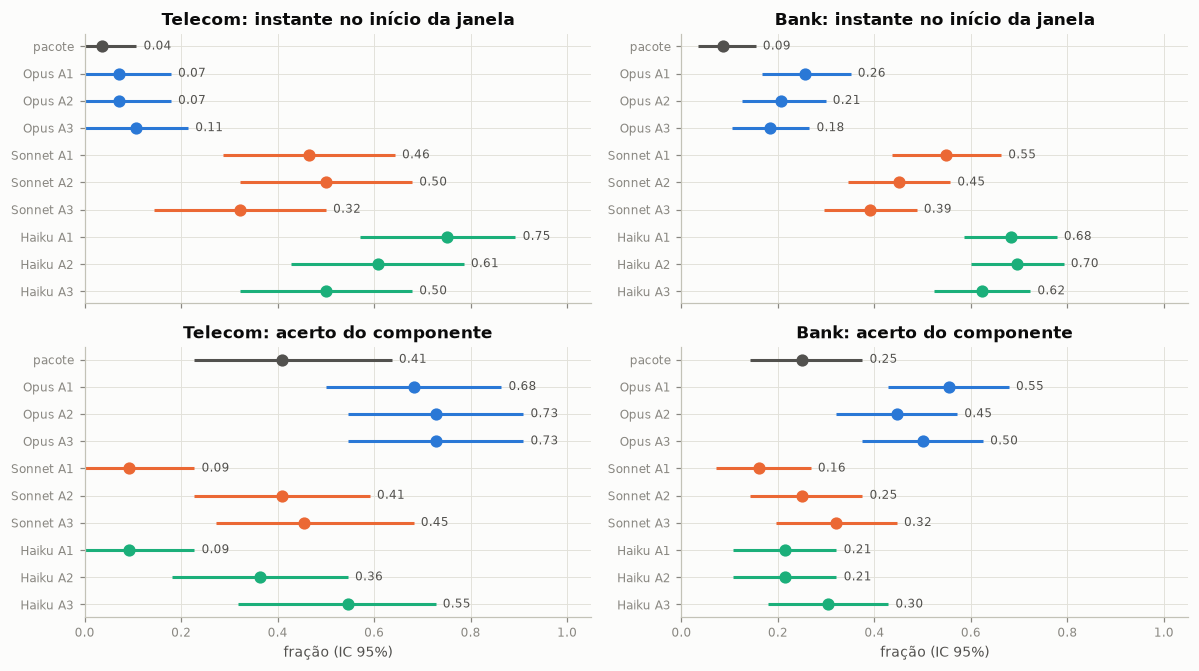

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex="col")
for row, (key, title) in enumerate(
    [("window_start", "instante no início da janela"), ("localization", "acerto do componente")]
):
    for col, s in enumerate(SYSTEMS):
        ax = axes[row, col]
        table = chain_table(s, key)
        chains = (["pacote"] if "pacote" in table else []) + LLM_CHAINS
        for i, c in enumerate(chains):
            e = table[c]
            dot_ci(ax, e, i, color(c))
            ax.text(
                e["ci_high"] + 0.015, i, f"{e['value']:.2f}", va="center", fontsize=8, color=INK2
            )
        ax.set_yticks(range(len(chains)), chains)
        ax.invert_yaxis()
        ax.set_xlim(0, 1.05)
        ax.set_title(f"{s}: {title}")
axes[1, 0].set_xlabel("fração (IC 95%)")
axes[1, 1].set_xlabel("fração (IC 95%)")
fig.tight_layout()

display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "cadeia": c,
                **{
                    f"{f} = pacote": f"{fmt(a[f])} (n={a[f]['n']})"
                    for f in ["instante", "componente", "motivo"]
                },
            }
            for s in SYSTEMS
            for c, a in chain_table(s, "package_agreement").items()
        ]
    )
)

**Leitura:**
- **Instante:** os modelos mais baratos continuam respondendo o início da janela.
  - **Haiku:** de 50% a 75% das vezes.
  - **Sonnet:** de 32% a 55%.
  - **Opus:** de 7% a 26%.
  - **Pacote:** de 4% a 9%.
  - A evidência reduz essa falha só em parte.
- **Componente:** é onde a evidência mais ajuda. No Telecom, o acerto vai de 0,09 (A1) para 0,45 a 0,55 (A3), mas o Opus chega a 0,73.
- **Concordância com o pacote:** o A3 dos modelos mais baratos repete o componente do pacote tanto quanto o Opus A3 ou mais. Parte do ganho vem de adotar a evidência, não de raciocinar sobre ela.

## 6. Custo × nota

- **Custo:** total da execução dividido pelo número de consultas.
- **Exceção, Sonnet A3 no Bank:** a execução parou por falta de crédito na 51ª consulta, ao custo de US$ 2,70, e foi refeita a partir do cache. A tabela registra só os US$ 3,73 da segunda execução, então o valor abaixo soma as duas partes (ADR 0023, adendo).

sistema,cadeia,custo total (US$),por consulta (US$),nota parcial
str,str,f64,f64,f64
"""Telecom""","""Opus A1""",8.69,0.1931,0.5962
"""Telecom""","""Opus A2""",7.55,0.1678,0.6038
"""Telecom""","""Opus A3""",7.3,0.1623,0.578
"""Telecom""","""Sonnet A1""",1.97,0.0437,0.174
"""Telecom""","""Sonnet A2""",1.56,0.0347,0.2442
"""Telecom""","""Sonnet A3""",2.12,0.047,0.3149
"""Telecom""","""Haiku A1""",0.28,0.0062,0.1369
"""Telecom""","""Haiku A2""",0.29,0.0064,0.2556
"""Telecom""","""Haiku A3""",0.26,0.0058,0.3404


modelo,custo das 6 execuções (US$)
str,f64
"""Opus""",103.88
"""Sonnet""",21.48
"""Haiku""",3.35


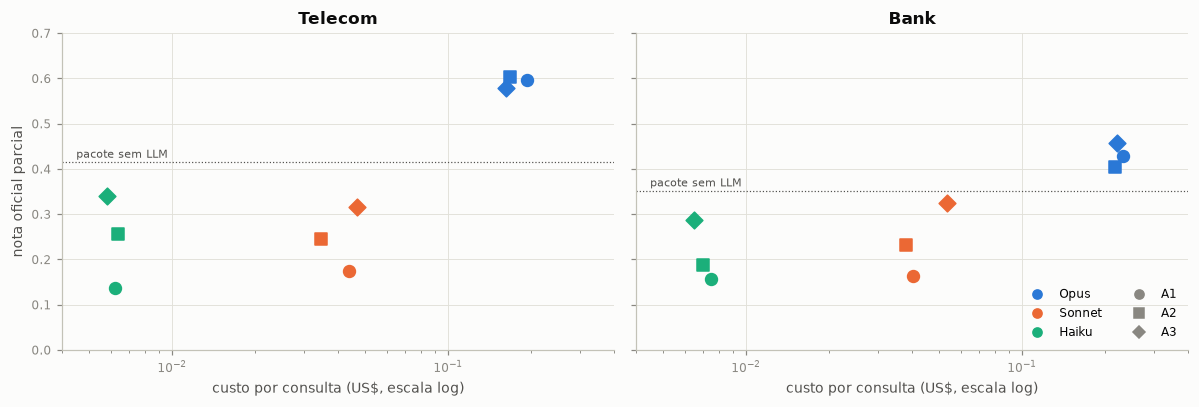

In [8]:
INTERRUPTED_USD = {("Bank", "Sonnet A3"): 2.70}  # ADR 0023, adendo: primeira execução, interrompida

rows = []
for s in SYSTEMS:
    cost = chain_table(s, "cost")
    summary = chain_table(s, "summary")
    n = M[(s, "Haiku")]["queries"]
    for c in LLM_CHAINS:
        total = cost[c]["cost_usd"] + INTERRUPTED_USD.get((s, c), 0.0)
        rows.append(
            {
                "sistema": s,
                "cadeia": c,
                "custo total (US$)": round(total, 2),
                "por consulta (US$)": round(total / n, 4),
                "nota parcial": summary[c]["partial_score"]["value"],
            }
        )
costs = pl.DataFrame(rows)
display(costs)
display(
    costs.with_columns(pl.col("cadeia").str.split(" ").list.first().alias("modelo"))
    .group_by("modelo", maintain_order=True)
    .agg(pl.col("custo total (US$)").sum().round(2).alias("custo das 6 execuções (US$)"))
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s in zip(axes, SYSTEMS, strict=True):
    sub = costs.filter(pl.col("sistema") == s)
    for r in sub.iter_rows(named=True):
        m, v = r["cadeia"].split()
        ax.scatter(
            r["por consulta (US$)"],
            r["nota parcial"],
            color=MODEL_COLOR[m],
            marker=MARKER[v],
            s=60,
            zorder=3,
        )
    pkg = chain_table(s, "summary")["pacote"]["partial_score"]["value"]
    ax.axhline(pkg, color=INK2, lw=0.8, ls=":")
    ax.text(0.0045, pkg + 0.01, "pacote sem LLM", fontsize=7, color=INK2)
    ax.set_xscale("log")
    ax.set_xlim(0.004, 0.4)
    ax.set_ylim(0, 0.7)
    ax.set_title(s)
    ax.set_xlabel("custo por consulta (US$, escala log)")
axes[0].set_ylabel("nota oficial parcial")
handles = [plt.Line2D([], [], ls="", marker="o", color=MODEL_COLOR[m], label=m) for m in MODELS] + [
    plt.Line2D([], [], ls="", marker=MARKER[v], color=MUTED, label=v) for v in VARIANTS
]
axes[1].legend(handles=handles, loc="lower right", ncol=2)
fig.tight_layout()

**Leitura:**
- **Gráfico:** cor = modelo, marcador = variante; os valores exatos estão na tabela acima.
- **Custo por consulta:** o Haiku custa cerca de 30 vezes menos que o Opus, e o Sonnet de 4 a 5 vezes menos.
- **Nota:** as duas economias levam ao mesmo patamar, o da cadeia do pacote, que não custa nada de LLM.
- **Neste estudo,** a nota acompanha o modelo, não a quantidade de evidência.

## 7. Fidelidade automática (sem gabarito)

As checagens são as mesmas da E8:
- IDs `T#`/`C#`/`K#`/`N#` citados que não foram emitidos;
- nomes de componente e KPI que não existem;
- números da explicação sem correspondência nas saídas das ferramentas.

O controle ×1,37 mede quanto a regra dos números deixa passar por acaso.

In [9]:
def rate(x):
    return f"{x['flagged']}/{x['checked']}"


display(
    pl.DataFrame(
        [
            {
                "sistema": s,
                "cadeia": c,
                "IDs não emitidos": rate(f["ids"]),
                "componentes desconhecidos": rate(f["components"]),
                "KPIs desconhecidos": rate(f["identifiers"]),
                "números sem correspondência": rate(f["numbers"]),
                "controle x1,37 casado": round(f["numbers"]["control_grounded_rate"], 2),
            }
            for s in SYSTEMS
            for m in CANDIDATES
            for c, f in M[(s, m)]["fidelity"].items()
        ]
    )
)

sistema,cadeia,IDs não emitidos,componentes desconhecidos,KPIs desconhecidos,números sem correspondência,"controle x1,37 casado"
str,str,str,str,str,str,f64
"""Telecom""","""Sonnet A1""","""0/173""","""0/181""","""0/196""","""12/131""",0.24
"""Telecom""","""Sonnet A2""","""0/172""","""0/191""","""0/178""","""1/187""",0.12
"""Telecom""","""Sonnet A3""","""0/398""","""0/226""","""0/175""","""4/210""",0.17
"""Telecom""","""Haiku A1""","""0/416""","""1/296""","""0/301""","""9/231""",0.38
"""Telecom""","""Haiku A2""","""0/515""","""0/303""","""0/289""","""5/272""",0.35
"""Telecom""","""Haiku A3""","""0/565""","""0/264""","""1/302""","""7/286""",0.31
"""Bank""","""Sonnet A1""","""0/385""","""0/505""","""0/45""","""2/413""",0.15
"""Bank""","""Sonnet A2""","""0/553""","""0/565""","""0/24""","""4/577""",0.11
"""Bank""","""Sonnet A3""","""0/1082""","""0/541""","""0/45""","""5/637""",0.11


**Leitura:**
- Nenhum modelo mais barato cita ID que não recebeu.
- Componentes e KPIs inventados são raros (no máximo 5 em 116 no Haiku A1 do Bank).
- Números sem correspondência ficam abaixo de 4%, com uma exceção: 9% (12/131) no Sonnet A1 do Telecom.
- Os modelos mais baratos erram por escolher mal o instante e o componente, não por inventar evidência.

## 8. Conclusões (exploratórias)

1. **Nenhum modelo mais barato iguala o Opus** com as ferramentas da A2/A3. Todas as comparações saem inferiores pelo veredito pareado, e nenhuma passa na não inferioridade com margem de 0,10.
2. **A evidência LSTM/XAI ajuda os modelos mais fracos.** A3 − A1 fica entre +0,13 e +0,20, superior em 3 de 4 casos. No Opus não há efeito. Uma leitura possível: a evidência supre o que o modelo não encontra sozinho, sobretudo o componente, e um modelo forte já o encontra.
3. **O teto prático dos modelos mais baratos é a própria evidência.** O A3 deles empata com a cadeia do pacote sem LLM. Eles não acrescentam raciocínio detectável sobre ela, e o instante no início da janela continua sendo a falha dominante.
4. **Custo:** neste estudo, gastar mais no modelo rendeu mais do que dar mais evidência a um modelo barato.
5. **Limites:**
   - análise decidida depois de ver o teste (ameaça nº 27);
   - 1 repetição;
   - 45 consultas no Telecom;
   - a comparação Sonnet × Haiku é só descritiva;
   - sem auditoria manual da fidelidade dos modelos mais baratos.

   O efeito da evidência nos modelos mais fracos é uma hipótese a confirmar, não uma conclusão principal.